# 15 · Regional grids, 3D maps, and sea-level time cubes

**Time:** 50 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** Map actual gridded projections, compare spatial support with gauges, and interpret the vertical axis correctly.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=15_ar6_grid_maps.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


> **Data identity:** real modeled projections, not observations. AR6 v20210809; workflow `wf_1e`; 20,000 Monte Carlo samples at each decade from 2020 to 2100. Source values are millimetres of relative sea-level change from the 1995–2014 reference period; plots convert them to metres. Background land motion is included.

> **Interpretation:** a workflow distribution is not the assessed IPCC probability box (p-box). The source FAQ says `wf_1e` does not preserve time correlations: do not calculate rates, sample trajectories, or first-crossing dates. The exercise compares distributions at specified years. These data alone cannot map inundation or rank port vulnerability.

![From archive chunks to projection distributions, with flood-risk evidence kept separate](assets/ar6-workflow.svg)

In [2]:
from ar6 import load_ar6, coverage_map, coastline, gauge_summary, summary_sql, export_summary
p, years, gauge_m, grid_m = load_ar6()
print('Samples: scenario, sample, year, unique gauge =', gauge_m.shape)
print('Nearest defined grid samples: sample, year, city =', grid_m.shape)

Samples: scenario, sample, year, unique gauge = (2, 20000, 9, 4)
Nearest defined grid samples: sample, year, city = (20000, 9, 5)


## 1. Change spatial support explicitly

For each city, we extracted a **5 × 5 one-degree window**, with no interpolation, for SSP5-8.5 / `wf_1e`. Each map value is the median of all 20,000 samples at one location and year. Missing locations remain NaN.

The authors explain that some projections are defined over apparent land because of differing model land/ocean masks. No additional coastline mask is applied here. Coloured cells indicate regional projection locations and their display footprint; they do not delineate water, flooded land, or a one-degree asset polygon. Natural Earth outlines are only geographic orientation.

Abidjan {'lat': 5.0, 'lon': -4.0, 'distance_km': 35.651293630083764, 'window_defined_locations': 25, 'window_locations': 25}
Lagos {'lat': 6.0, 'lon': 3.0, 'distance_km': 66.04752270171181, 'window_defined_locations': 25, 'window_locations': 25}
Bangkok {'lat': 14.0, 'lon': 100.0, 'distance_km': 60.211165800527176, 'window_defined_locations': 23, 'window_locations': 25}
Ho Chi Minh City {'lat': 11.0, 'lon': 107.0, 'distance_km': 40.88405364267304, 'window_defined_locations': 24, 'window_locations': 25}
Manila {'lat': 15.0, 'lon': 121.0, 'distance_km': 44.52997117192019, 'window_defined_locations': 25, 'window_locations': 25}


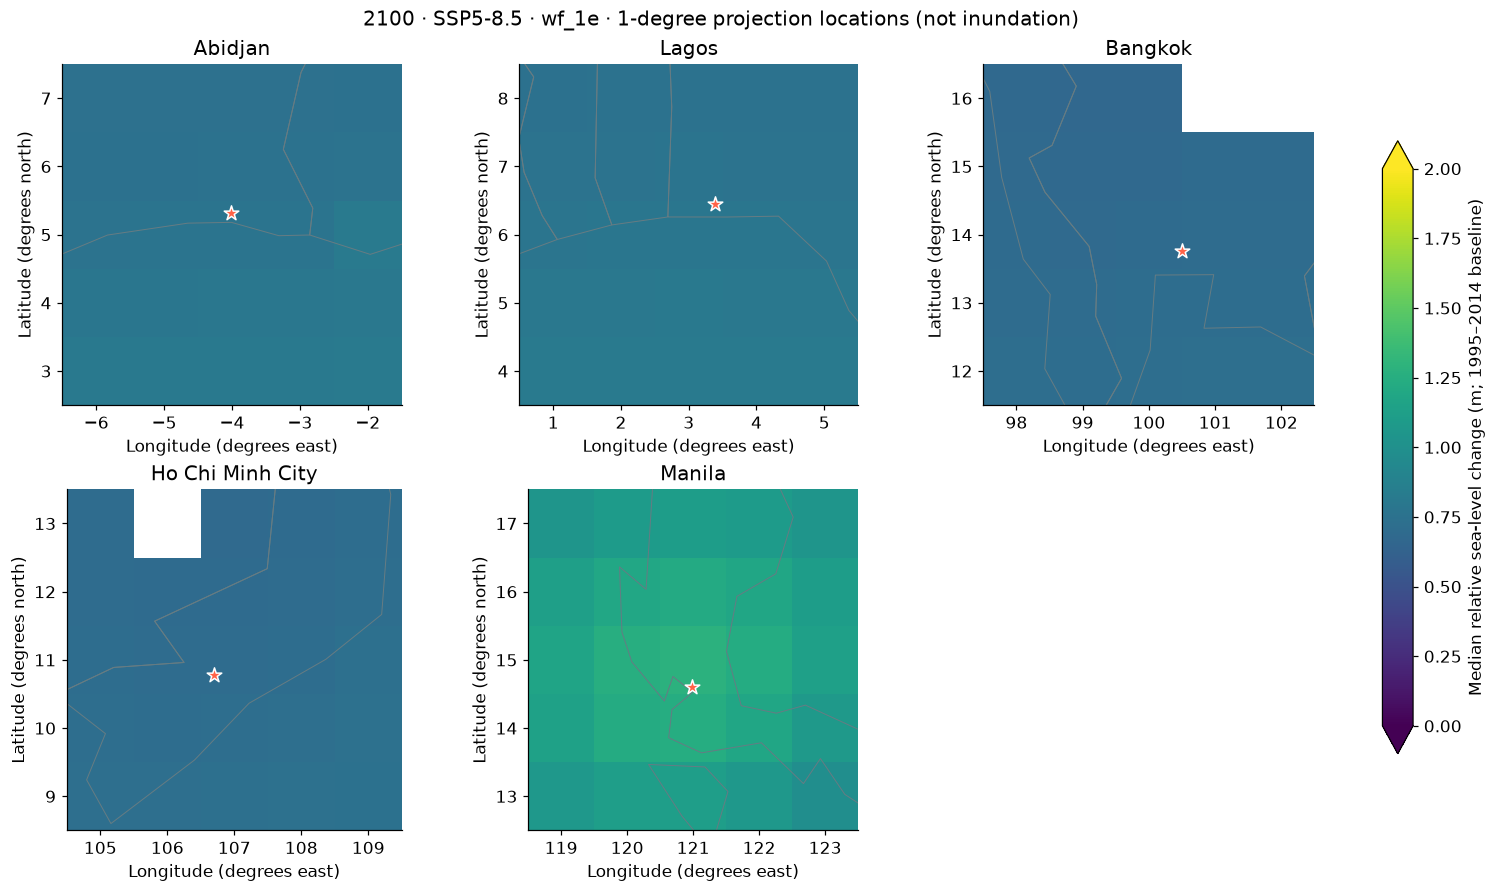

In [3]:
for c in p['cities']:
    print(c['name'],c['grid'])
fig,axes=plt.subplots(2,3,figsize=(14,8),constrained_layout=True)
for ax,c in zip(axes.flat,p['cities']):
    meta,values=load_cube('ar6_'+c['id'])
    image=ax.pcolormesh(meta['lon'],meta['lat'],values[-1],vmin=0,vmax=2,cmap='viridis',shading='nearest')
    coastline(ax); ax.scatter(c['lon'],c['lat'],marker='*',s=100,c='tomato',edgecolors='white',zorder=4)
    ax.set(xlim=(min(meta['lon'])-.5,max(meta['lon'])+.5),ylim=(min(meta['lat'])-.5,max(meta['lat'])+.5),title=c['name'])
    ax.set_aspect(1/np.cos(np.radians(c['lat'])))
axes.flat[-1].axis('off')
fig.colorbar(image,ax=list(axes.flat[:5]),label='Median relative sea-level change (m; 1995–2014 baseline)',extend='both',shrink=.8)
fig.suptitle('2100 · SSP5-8.5 · wf_1e · 1-degree projection locations (not inundation)')
plt.show()

## 2. Compare the nearest defined grid location and the proxy gauge

The nearest defined grid location is selected within the stated window using great-circle distance, requiring complete samples at all nine years. It is not automatically an offshore or hydraulically connected location. The scatter chart uses the **same workflow, scenario and year** for both products. A difference can reflect spatial support and model background processes; it cannot isolate local subsidence.

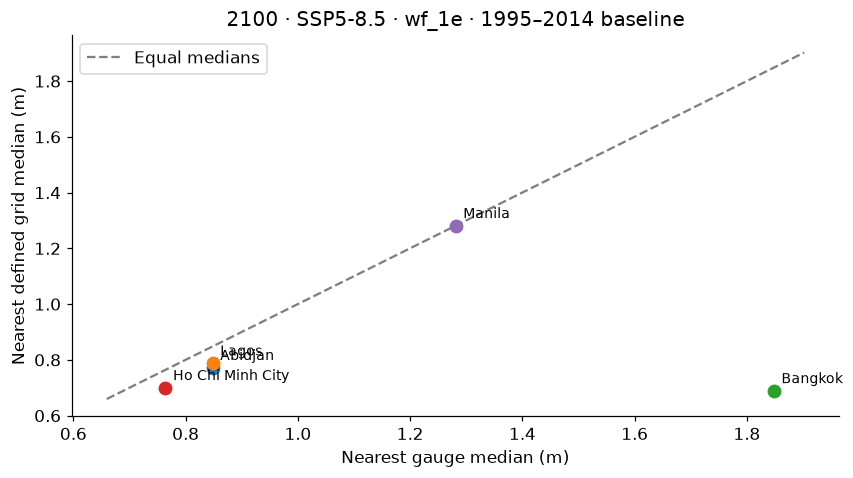

In [4]:
t=-1
fig,ax=plt.subplots()
for i,c in enumerate(p['cities']):
    gm=np.median(gauge_m[1,:,t,c['gauge_column']]); xm=np.median(grid_m[:,t,i])
    ax.scatter(gm,xm,s=65);ax.annotate(c['name'],(gm,xm),xytext=(5,5),textcoords='offset points',fontsize=9)
limits=[min(ax.get_xlim()[0],ax.get_ylim()[0]),max(ax.get_xlim()[1],ax.get_ylim()[1])]
ax.plot(limits,limits,'--',c='grey',label='Equal medians')
ax.set(xlabel='Nearest gauge median (m)',ylabel='Nearest defined grid median (m)',title='2100 · SSP5-8.5 · wf_1e · 1995–2014 baseline')
ax.legend();plt.show()

## 3. Use SQL to select regional cell-years

Change the city and threshold. `t=8` means 2100; this is an index, not a year literal. The 3D lab reads the same real Zarr median values and identifies them as **PROJECTIONS**. The default includes every finite value, including a negative value if one exists.

In [5]:
city_id='lagos'
meta,values=load_cube('ar6_'+city_id)
con=sql_connection(meta,values)
rows=list(con.execute('SELECT t, COUNT(value), MIN(value), MAX(value) FROM cells GROUP BY t ORDER BY t'))
for row in rows: print(meta['times'][row[0]],*row[1:])
con.close()
lab('ar6_'+city_id,'columns')

2020 25 0.054999999701976776 0.06400000303983688
2030 25 0.10499999672174454 0.11999999731779099
2040 25 0.164000004529953 0.18700000643730164
2050 25 0.23800000548362732 0.2669999897480011
2060 25 0.31299999356269836 0.3490000069141388
2070 25 0.40400001406669617 0.4480000138282776
2080 25 0.5019999742507935 0.5529999732971191
2090 25 0.6200000047683716 0.6809999942779541
2100 25 0.7490000128746033 0.8195000290870667


## 4. Rotate a time cube, then return to a 2D map

Use the lab's dataset menu for all five cities. In **3D map**, height is a visual scaling of median sea-level change, not terrain or water depth. In **time cube**, vertical position is decade index. **Value surface** is another scaled-value view, not a surveyed coastal scene. The animation steps between available decades; it does not simulate floods or storm dynamics.

Click one location to inspect its median sequence. Per-year medians form a summary curve, not a time-correlated realization. Separate city datasets have their own fixed colour ranges; use the common scale in the Python maps for cross-city magnitude comparisons.

In [6]:
lab('ar6_manila','cube')

## 5. Export for GeoLibre

Export the projection locations as GeoJSON points. Open the file in [GeoLibre Web](https://web.geolibre.app/) and style by value, with a year filter. Retain workflow, scenario, baseline and provenance. The exported geometry is a point sample; making a polygon or extruding it does not create an inundation model.

For African context, revisit [Digital Earth Africa's STAC catalog](https://explorer.digitalearth.africa/stac) and investigate coastal water observations. A WOfS frequency is not a terrain height, and its time support and observation masks differ from AR6 projections. Treat an overlay as a question to investigate, not validation of future flood extent.

In [7]:
print('Exported finite nonnegative cell-years:',export_geojson(meta,values,'ar6-lagos-grid.geojson',threshold=0))

Exported finite nonnegative cell-years: 225


## Try it yourself

Switch from Lagos to Abidjan and inspect the 2050/2100 maps. Which differences come from spatial support, scenario, statistic, or visual scale?

## Check your reasoning

Only spatial support and time change within these SSP5-8.5 median maps. Compare values on a shared colour scale and retain each location’s coordinates. Neither the source grid nor the extruded view resolves a port flood boundary.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [Fox-Kemper et al. (2021), IPCC AR6 WG1 Chapter 9: Ocean, Cryosphere and Sea Level Change](https://doi.org/10.1017/9781009157896.011).
- [Kopp et al. (2023), FACTS v1.0, Geoscientific Model Development 16, 7461–7489](https://doi.org/10.5194/gmd-16-7461-2023).
- [Garner et al. (2021), IPCC AR6 Sea Level Projections, version 20210809](https://doi.org/10.5281/zenodo.5914709), accessed 2026-10-13. Modified extracts under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
- [Rutgers-ESSP source guide and workflow FAQ](https://github.com/Rutgers-ESSP/IPCC-AR6-Sea-Level-Projections/tree/8ee75128d8f6d9a8ba9825f47c92d11955d0651e).
- [Exact source objects, checksums, transformations and location distances](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/ar6-provenance.json).
- We thank the projection authors for developing and making the sea-level rise projections available, multiple funding agencies for supporting the development of the projections, and the NASA Sea Level Change Team for developing and hosting the IPCC AR6 Sea Level Projection Tool.
- [Natural Earth boundary data, public domain](https://www.naturalearthdata.com/about/terms-of-use/).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [8]:
print('LESSON COMPLETE: 15_ar6_grid_maps')

LESSON COMPLETE: 15_ar6_grid_maps
